# Extract Civilization II scenario maps

Place the scenario files in the same folder as this notebook. Change the filenames below and run the cells. Each map is exported as a fresh `.MP` file for use with the map-scaling notebook. Requires NumPy and Matplotlib.

In [2]:
from pathlib import Path
import struct

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.patches import Patch

In [11]:
# Settings
input_files = [Path("SCENARIO/SAMURAI/SAMURAI.SCN")]
output_directory = Path("extracted_maps")
map_layers = None       # None exports every map; [0] exports only the primary map.
                       # Map numbers begin at 0. Multiple layers occur in Test of Time.

The reader detects Classic/Conflicts in Civilization, Fantastic Worlds, Multiplayer Gold, and standard Test of Time 1.0/1.1 files. It preserves terrain slots, rivers, world shape, resource seed and resource-suppression flags. Each Test of Time layer becomes a separate `.MP` file.

Cities, units, ownership, improvements and scenario events are removed. Starting positions are left unassigned. Custom terrain names, rules and graphics are separate files and are not included in the exported map.

In [12]:
# Read the version-specific header and map blocks.
VERSIONS = {
    39: "Classic / Conflicts in Civilization",
    40: "Fantastic Worlds",
    44: "Multiplayer Gold",
    49: "Test of Time 1.0",
    50: "Test of Time 1.1",
}


def require_bytes(data, offset, length, description):
    if offset < 0 or offset + length > len(data):
        raise ValueError(f"File is truncated or has an unsupported layout: {description}.")


def read_scenario_maps(data, filename):
    """Read standard Civ2 SCN/SAV layouts; return one dictionary per map layer."""
    require_bytes(data, 0, 12, "file header")
    if data[:10] != b"CIVILIZE\x00\x1a":
        raise ValueError(f"{filename}: not a recognized Civilization II scenario/save file.")
    version = struct.unpack_from("<H", data, 10)[0]
    if version not in VERSIONS:
        raise ValueError(f"{filename}: unsupported format version {version}.")

    if version in (39, 40, 44):
        header_offset = 0x3478 if version == 39 else 0x3586
        header_size = 14
        shape_offset = 13
    else:
        # ToT stores transporter pairs before its map header. Version 1.1 also
        # stores a 168-byte LEADERS2 table before the transporter count.
        transporter_offset = 29728 if version == 49 else 29896
        require_bytes(data, transporter_offset, 4, "transporter count")
        transporters = struct.unpack_from("<H", data, transporter_offset)[0]
        header_offset = transporter_offset + 4 + 14 * transporters
        header_size = 16
        shape_offset = 653

    require_bytes(data, header_offset, header_size, "map header")
    coord_width, height, area, header_flat, header_seed, mw, mh = struct.unpack_from(
        "<7H", data, header_offset
    )
    if coord_width == 0 or coord_width % 2 or height == 0:
        raise ValueError(f"{filename}: invalid map dimensions.")
    width = coord_width // 2
    if area != width * height or header_flat not in (0, 1):
        raise ValueError(f"{filename}: inconsistent map header.")
    if (mw, mh) != ((coord_width + 3) // 4, (height + 3) // 4):
        raise ValueError(f"{filename}: unexpected minimap dimensions; check the file layout.")

    number_of_maps = 1
    if version in (49, 50):
        secondary_maps = struct.unpack_from("<H", data, header_offset + 14)[0]
        if secondary_maps > 3:
            raise ValueError(f"{filename}: unsupported number of secondary maps: {secondary_maps}.")
        number_of_maps += secondary_maps

    # The game-option flag is authoritative if the map-header copy is stale.
    require_bytes(data, shape_offset, 1, "world-shape option")
    flat = int(bool(data[shape_offset] & 0x80))
    maps_offset = header_offset + header_size
    stride = 13 * area + (2 if version in (49, 50) else 0)
    require_bytes(data, maps_offset, number_of_maps * stride + 2 * mw * mh, "map layers")

    maps = []
    for layer in range(number_of_maps):
        layer_offset = maps_offset + layer * stride
        terrain_offset = layer_offset + 7 * area
        records = np.frombuffer(data, dtype=np.uint8, count=6 * area,
                                offset=terrain_offset).reshape(area, 6).copy()
        terrain = records[:, 0]
        if np.any((terrain & 15) > 10):
            raise ValueError(f"{filename}, map {layer}: invalid terrain slots or an unsupported layout.")
        seed = header_seed
        if version in (49, 50):
            seed = struct.unpack_from("<H", data, terrain_offset + 6 * area)[0]
        maps.append({"filename": str(filename), "version": version,
                     "version_name": VERSIONS[version], "layer": layer,
                     "number_of_maps": number_of_maps, "width": width, "height": height,
                     "flat": flat, "seed": seed, "records": records,
                     "header_offset": header_offset, "terrain_offset": terrain_offset})
    return maps

In [13]:
# Build and check a terrain-only MP file.
def make_mp_bytes(world):
    """Export a fresh terrain map with rivers, seed and resource suppression flags."""
    width, height = world["width"], world["height"]
    area = width * height
    records = np.zeros((area, 6), dtype=np.uint8)
    # Keep the terrain slot, no-resource bit and river bit. Remove animation state.
    records[:, 0] = world["records"][:, 0] & 0xCF
    records[:, 4] = records[:, 0]
    records[:, 5] = 0xF0
    header = struct.pack("<7H", 2 * width, height, area, world["flat"], world["seed"],
                         (2 * width + 3) // 4, (height + 3) // 4)
    # SCN/SAV files store a running game, not the 21 initial-position pairs in MP.
    # Leave starts unassigned, allowing a new game to choose them.
    starts = struct.pack("<42h", *([-1] * 42))
    return header + starts + records.tobytes()


def check_mp_bytes(data, world):
    """Verify dimensions and every terrain/river flag against the scenario map."""
    width, height = world["width"], world["height"]
    area = width * height
    if len(data) != 98 + 6 * area:
        raise ValueError("Exported MP file has the wrong length.")
    expected_header = (2 * width, height, area, world["flat"], world["seed"],
                       (2 * width + 3) // 4, (height + 3) // 4)
    if struct.unpack_from("<7H", data) != expected_header:
        raise ValueError("Exported map header does not match the source.")
    if struct.unpack_from("<42h", data, 14) != tuple([-1] * 42):
        raise ValueError("Starting positions should be unassigned.")
    records = np.frombuffer(data, dtype=np.uint8, offset=98).reshape(area, 6)
    if not np.array_equal(records[:, 0], world["records"][:, 0] & 0xCF):
        raise ValueError("Export changed the terrain, river or resource suppression flags.")
    if np.any(records[:, 1:4]) or not np.all(records[:, 5] == 0xF0):
        raise ValueError("Scenario state remains in the exported map.")
    if not np.array_equal(records[:, 4], records[:, 0]):
        raise ValueError("Exported map-editor terrain copy is inconsistent.")

In [14]:
# Read the input files and select map layers.
extracted_maps = []
for input_file in input_files:
    file_maps = read_scenario_maps(input_file.read_bytes(), input_file)
    first = file_maps[0]
    print(f"{input_file.name}: {first['version_name']} (version {first['version']})")
    print(f"  {first['width']} × {first['height']} = {first['width'] * first['height']:,} tiles; "
          f"{len(file_maps)} map(s); {'flat' if first['flat'] else 'wraps horizontally'}")

    if map_layers is not None:
        if not map_layers or any(not isinstance(layer, int) or not 0 <= layer < len(file_maps)
                                 for layer in map_layers):
            raise ValueError(f"Invalid map_layers for {input_file.name}; valid maps are 0..{len(file_maps) - 1}.")
        if len(set(map_layers)) != len(map_layers):
            raise ValueError("map_layers contains duplicate map numbers.")
        file_maps = [file_maps[layer] for layer in map_layers]
    extracted_maps.extend(file_maps)

if not extracted_maps:
    raise ValueError("No maps selected. Add at least one filename to input_files.")

for world in extracted_maps:
    rivers = np.count_nonzero(world["records"][:, 0] & 128)
    print(f"  {Path(world['filename']).stem}, map {world['layer']}: {rivers:,} river tiles; seed {world['seed']}")

SAMURAI.SCN: Fantastic Worlds (version 40)
  50 × 120 = 6,000 tiles; 1 map(s); flat
  SAMURAI, map 0: 162 river tiles; seed 7063


In [15]:
# Preview terrain using the standard Civ2 colors and names for slots 0..10.
# A scenario may redefine the meaning or artwork of these slots in RULES.TXT.
terrain_names = ["Desert", "Plains", "Grassland", "Forest", "Hills", "Mountains",
                 "Tundra", "Glacier", "Swamp", "Jungle", "Ocean"]
terrain_colors = ["#d9bd7b", "#c9c177", "#70b952", "#306847", "#958853", "#796e60",
                  "#bec6aa", "#f0f5f5", "#548b7f", "#24583e", "#3975ae"]


def plot_map(ax, world):
    width, height = world["width"], world["height"]
    rows, cols = np.indices((height, width))
    centers = np.column_stack(((2 * cols + rows % 2).ravel(), rows.ravel()))
    diamonds = np.array([[-1, 0], [0, -1], [1, 0], [0, 1]])
    terrain = world["records"][:, 0]
    colors = np.array(terrain_colors)[terrain & 15]
    ax.add_collection(PolyCollection(centers[:, None, :] + diamonds,
                                     facecolors=colors, edgecolors="none", antialiased=False))
    # Mark river tiles with small blue diamonds; no flow direction is inferred.
    river_centers = centers[(terrain & 128) != 0]
    ax.add_collection(PolyCollection(river_centers[:, None, :] + 0.25 * diamonds,
                                     facecolors="#064fce", edgecolors="none"))
    ax.set_xlim(-1, 2 * width)
    ax.set_ylim(height, -1)
    ax.set_aspect(0.5)
    ax.set_title(f"{Path(world['filename']).stem}: map {world['layer']} ({width} × {height})")
    ax.axis("off")

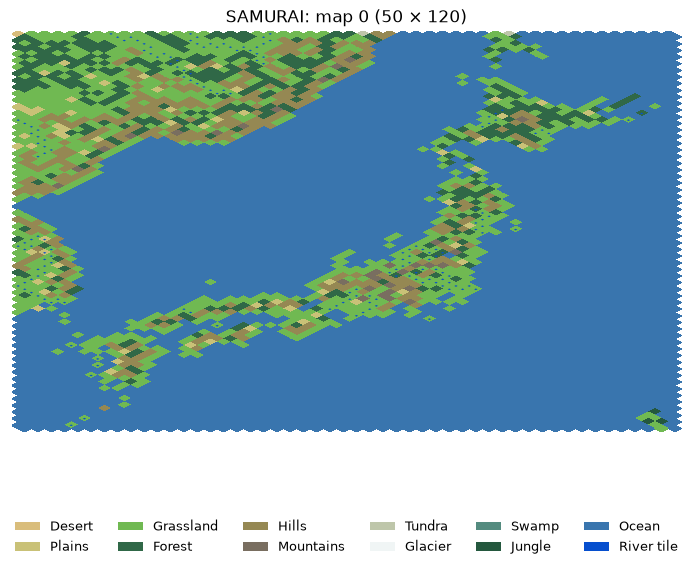

In [16]:
columns = min(2, len(extracted_maps))
rows = (len(extracted_maps) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(7 * columns, 5 * rows + 1), squeeze=False)
for ax, world in zip(axes.ravel(), extracted_maps):
    plot_map(ax, world)
for ax in axes.ravel()[len(extracted_maps):]:
    ax.axis("off")

legend = [Patch(facecolor=color, label=name) for color, name in zip(terrain_colors, terrain_names)]
legend.append(Patch(facecolor="#064fce", label="River tile"))
fig.legend(handles=legend, loc="lower center", ncol=6, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.10 / rows, 1, 1))
plt.show()

In [17]:
# Save and verify the MP files. Rerunning replaces the generated maps.
output_paths = []
for world in extracted_maps:
    stem = Path(world["filename"]).stem
    suffix = f"_map{world['layer']}" if world["number_of_maps"] > 1 else ""
    output_paths.append(output_directory / f"{stem}{suffix}.MP")
if len({path.resolve() for path in output_paths}) != len(output_paths):
    raise ValueError("Two inputs would create the same output name. Use separate output folders.")

output_directory.mkdir(parents=True, exist_ok=True)
for world, destination in zip(extracted_maps, output_paths):
    result = make_mp_bytes(world)
    check_mp_bytes(result, world)
    destination.write_bytes(result)
    check_mp_bytes(destination.read_bytes(), world)
    print(f"Saved {destination}: {world['width'] * world['height']:,} tiles, {len(result):,} bytes")

print("Terrain, rivers, seeds and MP structure checked. The original scenario files were not modified.")

Saved extracted_maps\SAMURAI.MP: 6,000 tiles, 36,098 bytes
Terrain, rivers, seeds and MP structure checked. The original scenario files were not modified.
